# Eksperimen Pribadi — Tugas 3 Bagian B.iii: Pemfilteran Tingkat Entitas (NER)

> "Pemfilteran tingkat entitas (Named Entity Recognition/NER) yang berfokus pada negara, bank sentral, dan peristiwa ekonomi."

**Ide:** tidak semua berita sama relevannya untuk USD/IDR. Berita yang menyebut The Fed atau bank sentral lain, atau peristiwa ekonomi (suku bunga, inflasi, tarif), kemungkinan lebih relevan daripada berita lain. NER dipakai untuk **mengenali dan menyaring** entitas itu, lalu fitur diambil dari entitas dan dari berita yang memuatnya.

**Tiga hipotesis:**
1. **H1 — perhatian berita:** porsi berita harian yang menyebut negara tertentu / bank sentral / peristiwa ekonomi tertentu memberi informasi di luar fitur kurs.
2. **H2 — sentimen terfilter:** sentimen khusus berita bank sentral / peristiwa ekonomi / AS lebih informatif daripada sentimen semua berita.
3. **H3 — kualitas ekstraksi:** NER + kamus cukup andal (cakupan, presisi pada sampel, kesalahan NER mentah).

**Cara ekstraksi (penting dipahami):**
- **Negara & bank sentral:** spaCy NER menemukan kandidat (`GPE`, `NORP`, `LOC`, `ORG`, `PERSON`), lalu **kamus alias** memetakan ke entitas kanonik (mis. "Beijing", "Chinese" → China) dan membuang yang bukan target (mis. "AI", "CNBC"). Untuk bank sentral, hasil NER juga **digabung dengan pencarian kamus pada teks** karena NER sering meleset pada singkatan.
- **Peristiwa ekonomi:** label `EVENT` bawaan spaCy hampir tidak memuat peristiwa ekonomi, jadi dipakai **aturan berbasis pola kata** (rate decision, inflasi, tarif, sanksi, resesi, dst.).

| Set | Fitur |
|---|---|
| **A / B** | kurs / kurs + 16 lexicon (acuan) |
| **G** | A + sentimen FinBERT global (acuan H2, bila cache ada) |
| **E1 negara** | A + porsi berita harian untuk 8 negara/kawasan terbesar |
| **E2 bank sentral** | A + 3 porsi (semua bank sentral, The Fed, bank sentral lain) |
| **E3 peristiwa** | A + porsi berita harian untuk 11 jenis peristiwa ekonomi |
| **E-semua** | A + E1 + E2 + E3 |
| **F sentimen terfilter** | A + sentimen rata-rata hanya dari berita bank sentral / peristiwa ekonomi / AS |
| **E2+F** | A + E2 + F |

**Aturan:** kamus dibuat dari pengamatan data (bukan dari performa val/test); tidak ada model yang di-fit pada val/test. Pembanding utama tetap baris Konstan.

**Prasyarat:** `pip install spacy` lalu unduh model: `python -m spacy download en_core_web_sm`. NER semua artikel makan beberapa menit pertama kali, lalu di-cache.

## 0. Setup

In [9]:
%pip install spacy
!python -m spacy download en_core_web_sm

Defaulting to user installation because normal site-packages is not writeable
  Using cached spacy-3.8.17.tar.gz (1.3 MB)
  Installing build dependencies ... error
  error: subprocess-exited-with-error
  
  × installing build dependencies for spacy did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
        Using cached setuptools-82.0.1-py3-none-any.whl.metadata (6.5 kB)
        Using cached cython-3.3.1-cp39-cp39-macosx_11_0_arm64.whl.metadata (13 kB)
        Using cached cymem-2.0.16-cp39-cp39-macosx_11_0_arm64.whl.metadata (9.7 kB)
        Using cached preshed-3.0.15-cp39-cp39-macosx_11_0_arm64.whl.metadata (5.3 kB)
        Using cached murmurhash-1.0.16-cp39-cp39-macosx_11_0_arm64.whl.metadata (2.3 kB)
      ERROR: Ignored the following yanked versions: 6.10.4.dev0, 7.4.4, 8.3.5
      ERROR: Ignored the following versions that require a different python version: 10.0.0 Requires-Python >=3.10,<3.16; 8.3.10 Requires-Python >=3.10,<3.15; 8.3.11 Requires-Python >=3.1

In [10]:
import sys, re, json, time, pickle, warnings
sys.dont_write_bytecode = True
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
warnings.filterwarnings("ignore")

def find_root():
    '''Cari root repo dari folder notebook (jalan dari notebook/ maupun src/notebook/).'''
    here = Path.cwd().resolve()
    for q in (here, *here.parents):
        if (q / "data" / "export" / "articles.parquet").exists() and (q / "src" / "eval_utils.py").exists():
            return q
    raise FileNotFoundError("root repo (data/export + src/eval_utils.py) tidak ditemukan dari " + str(here))

ROOT = find_root()
sys.path.append(str(ROOT / "src"))
from eval_utils import evaluate, naive_baselines

EXPORT_DIR = ROOT / "data" / "export"
CACHE_DIR = Path("cache_embeddings"); CACHE_DIR.mkdir(exist_ok=True)
SEED = 42
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
print("root repo:", ROOT)

root repo: /Users/farsyaant/nlpproject-baru


## 1. Muat data dan split (sama seperti notebook sebelumnya)

In [11]:
articles = pd.read_parquet(EXPORT_DIR / "articles.parquet").sort_values("article_id").reset_index(drop=True)
prices   = pd.read_parquet(EXPORT_DIR / "prices_daily.parquet")
sent     = pd.read_parquet(EXPORT_DIR / "sentiment_daily.parquet")
splits   = json.loads((EXPORT_DIR / "splits.json").read_text())

KURS_COLS = ["kurs_lag1", "kurs_lag2", "kurs_lag3", "kurs_lag4", "kurs_lag5", "kurs_roll_mean5", "kurs_roll_std5"]
LEX_COLS = [c for c in sent.columns if c not in ("date", "news_count")]
assert len(KURS_COLS) == 7 and len(LEX_COLS) == 16

daily = (prices.merge(sent[["date", "news_count"] + LEX_COLS], on="date", how="left")
               .sort_values("date").reset_index(drop=True))
assert daily[LEX_COLS].notna().all().all()
for s in ("train", "val", "test"):
    assert (daily["split"] == s).sum() == splits[s]["n"]
tr = (daily["split"] == "train").to_numpy(); va = (daily["split"] == "val").to_numpy(); te = (daily["split"] == "test").to_numpy()
y = daily["target"].to_numpy()

articles["split"] = articles["aligned_trading_date"].map(dict(zip(daily["date"], daily["split"])))
articles["text_raw"] = articles["title"].fillna("").str.strip() + ". " + articles["full_text"].fillna("").str.strip()
print("baris per split:", tr.sum(), va.sum(), te.sum())
print(articles["split"].value_counts(dropna=False).to_string())

baris per split: 836 178 180
split
train    2489
test     1220
val       619
NaN         4


## 2. Menjalankan NER (spaCy)

Model `en_core_web_sm` dijalankan pada seluruh teks (`title. full_text`). Hasil (daftar entitas per artikel) disimpan di `cache_embeddings/` supaya tidak diulang. NER tidak "belajar" dari data kita, jadi tidak ada kebocoran.

In [13]:
NER_MODEL = "en_core_web_sm"
ner_f = CACHE_DIR / f"ner_spacy_{NER_MODEL}.pkl"
texts = articles["text_raw"].tolist()
is_tr = (articles["split"] == "train").to_numpy()
has_split = articles["split"].notna().to_numpy()
ents = None
if ner_f.exists():
    saved = pickle.load(open(ner_f, "rb"))
    if saved["n"] == len(texts):
        ents = saved["ents"]; print(f"NER dimuat dari cache {ner_f.name}")
if ents is None:
    import spacy
    nlp = spacy.load(NER_MODEL, disable=["parser", "lemmatizer", "tagger", "attribute_ruler"])
    t0 = time.time(); ents = []
    for i, d in enumerate(nlp.pipe(texts, batch_size=32)):
        ents.append([(e.text, e.label_) for e in d.ents])
        if (i + 1) % 500 == 0:
            print(f"  {i + 1}/{len(texts)} artikel | {time.time() - t0:.0f}s", flush=True)
    pickle.dump({"n": len(texts), "model": NER_MODEL, "ents": ents}, open(ner_f, "wb"))
    print(f"NER selesai dalam {time.time() - t0:.0f}s")
print("label entitas terbanyak:", Counter(l for es in ents for _, l in es).most_common(8))

NER dimuat dari cache ner_spacy_en_core_web_sm.pkl
label entitas terbanyak: [('GPE', 105179), ('ORG', 78418), ('DATE', 66681), ('PERSON', 50533), ('NORP', 27702), ('CARDINAL', 20893), ('PERCENT', 17483), ('LOC', 13337)]


## 3. Kamus entitas: negara, bank sentral, peristiwa ekonomi

Kamus dibuat dari daftar entitas teratas pada data (lihat bagian 4) dan pengetahuan umum, **bukan** dari performa prediksi. Teks entitas dinormalisasi: huruf kecil, titik dibuang, awalan "the" dibuang ("the U.S." → "us").

In [14]:
def norm(s):
    s = s.lower().replace("’", "'").replace(".", "").strip()
    return re.sub(r"^the\s+", "", s)

COUNTRY_GROUPS = {   # kelompok -> alias (sudah dinormalisasi)
    "US": ["us", "united states", "america", "american", "americans", "usa", "washington", "white house", "pentagon"],
    "China": ["china", "chinese", "beijing"],
    "Russia": ["russia", "russian", "russians", "moscow", "kremlin"],
    "Ukraina": ["ukraine", "ukrainian", "ukrainians", "kyiv", "kiev", "crimea"],
    "Israel_Palestina": ["israel", "israeli", "israelis", "gaza", "palestinian", "palestinians", "palestine", "west bank", "hamas"],
    "Iran": ["iran", "iranian", "iranians", "tehran"],
    "Jepang": ["japan", "japanese", "tokyo"],
    "Eropa": ["eu", "european union", "europe", "european", "germany", "german", "france", "french", "brussels", "berlin", "paris"],
    "Inggris": ["uk", "united kingdom", "britain", "british", "london"],
    "India": ["india", "indian", "delhi", "new delhi"],
    "Teluk": ["saudi arabia", "saudi", "qatar", "uae", "united arab emirates", "kuwait", "gulf", "riyadh"],
    "Taiwan": ["taiwan", "taiwanese", "taipei"],
    "Korea": ["north korea", "south korea", "korea", "korean", "pyongyang", "seoul"],
    "Indonesia": ["indonesia", "indonesian", "jakarta", "rupiah"],
}
CB_GROUPS = {        # bank sentral -> alias NER (ORG / PERSON)
    "Fed": ["fed", "federal reserve", "fomc", "federal open market committee", "powell", "jerome powell"],
    "ECB": ["ecb", "european central bank", "lagarde", "christine lagarde"],
    "BOJ": ["boj", "bank of japan", "ueda", "kazuo ueda"],
    "BOE": ["boe", "bank of england", "andrew bailey"],
    "PBOC": ["pboc", "people's bank of china", "pbc"],
    "Lainnya": ["rba", "reserve bank of australia", "snb", "swiss national bank", "rbi", "reserve bank of india",
                "bank of canada", "bank indonesia", "bank of korea"],
}
CB_REGEX = {         # pencarian kamus langsung pada teks (singkatan peka huruf besar)
    "Fed": r"\b(Fed|Federal Reserve|FOMC|Powell)\b",
    "ECB": r"\b(ECB|European Central Bank|Lagarde)\b",
    "BOJ": r"\b(BOJ|Bank of Japan|Ueda)\b",
    "BOE": r"\b(BOE|Bank of England)\b",
    "PBOC": r"\b(PBOC|PBoC|People.s Bank of China)\b",
    "Lainnya": r"\b(RBA|Reserve Bank of Australia|SNB|Swiss National Bank|RBI|Reserve Bank of India|Bank of Canada|Bank Indonesia|Bank of Korea)\b",
}
ECON_EVENTS = {      # peristiwa ekonomi -> pola (tidak peka huruf besar)
    "keputusan_suku_bunga": r"\b(rate (hike|cut|increase|decrease)s?|(raise|raised|raising|cut|cuts|cutting|lower|lowered|hike|hiked|hold|held) (interest )?rates?)\b",
    "inflasi": r"\b(inflation|CPI|consumer price)\b",
    "pertumbuhan_PDB": r"\b(GDP|gross domestic product|economic growth)\b",
    "tarif_dagang": r"\b(tariffs?|trade war|trade deal)\b",
    "sanksi": r"\bsanctions?\b",
    "resesi": r"\b(recession|stagflation|downturn)\b",
    "tenaga_kerja": r"\b(jobs report|nonfarm|payrolls?|unemployment)\b",
    "utang_default": r"\b(default|debt ceiling|sovereign debt|credit rating|downgrade)\b",
    "minyak_energi": r"\b(oil prices?|crude|Brent|WTI|OPEC)\b",
    "krisis_bank": r"\b(bank failure|banking crisis|bank run|Credit Suisse|Silicon Valley Bank|SVB)\b",
    "mata_uang": r"\b(dollar|yen|yuan|currency|exchange rate|rupiah)\b",
}
ALIAS_C = {a: g for g, al in COUNTRY_GROUPS.items() for a in al}
ALIAS_CB = {a: g for g, al in CB_GROUPS.items() for a in al}
C_LABELS, CB_LABELS = {"GPE", "NORP", "LOC", "ORG"}, {"ORG", "PERSON"}

n = len(articles)
cg, cbg, evg = list(COUNTRY_GROUPS), list(CB_GROUPS), list(ECON_EVENTS)
C_FLAG = np.zeros((n, len(cg)), bool); CB_NER = np.zeros((n, len(cbg)), bool)
CB_RX = np.zeros((n, len(cbg)), bool); EV_FLAG = np.zeros((n, len(evg)), bool)
cb_rx_c = {g: re.compile(p) for g, p in CB_REGEX.items()}
ev_rx_c = {g: re.compile(p, re.I) for g, p in ECON_EVENTS.items()}
for i, (es, t) in enumerate(zip(ents, texts)):
    for s, lab in es:
        k = norm(s)
        if lab in C_LABELS and k in ALIAS_C: C_FLAG[i, cg.index(ALIAS_C[k])] = True
        if lab in CB_LABELS and k in ALIAS_CB: CB_NER[i, cbg.index(ALIAS_CB[k])] = True
    for j, g in enumerate(cbg): CB_RX[i, j] = bool(cb_rx_c[g].search(t))
    for j, g in enumerate(evg): EV_FLAG[i, j] = bool(ev_rx_c[g].search(t))
CB_FLAG = CB_NER | CB_RX                                   # gabungan NER + kamus teks
CB_ANY = CB_FLAG.any(1); CB_FED = CB_FLAG[:, cbg.index("Fed")]
CB_OTHER = CB_FLAG[:, [j for j, g in enumerate(cbg) if g != "Fed"]].any(1)
ECON_ANY = EV_FLAG.any(1); US_FLAG = C_FLAG[:, cg.index("US")]
print("kamus siap")

kamus siap


## 4. H3: seberapa andal ekstraksinya?

**4.1 Cakupan:** berapa % artikel memuat tiap kelompok. **4.2 Kesalahan NER mentah:** entitas negara/organisasi yang paling sering muncul tetapi **tidak** lolos kamus (kebanyakan noise). **4.3 NER vs kamus teks untuk bank sentral:** apakah NER saja cukup? **4.4 Label EVENT bawaan** (alasan peristiwa ekonomi pakai aturan pola). **4.5 Cek presisi manual:** cuplikan acak artikel yang ditandai "bank sentral", **kamu nilai sendiri** apakah benar.

In [15]:
cov = pd.concat([
    pd.Series(C_FLAG.mean(0), index=cg, name="% artikel").to_frame().assign(jenis="negara"),
    pd.Series(CB_FLAG.mean(0), index=cbg, name="% artikel").to_frame().assign(jenis="bank sentral"),
    pd.Series(EV_FLAG.mean(0), index=evg, name="% artikel").to_frame().assign(jenis="peristiwa ekonomi"),
])
cov["% artikel"] = (cov["% artikel"] * 100).round(1)
print(f"artikel menyebut >=1 bank sentral: {CB_ANY.mean():.1%} | >=1 peristiwa ekonomi: {ECON_ANY.mean():.1%} | AS: {US_FLAG.mean():.1%}")
cov.sort_values(["jenis", "% artikel"], ascending=[True, False])

artikel menyebut >=1 bank sentral: 22.2% | >=1 peristiwa ekonomi: 72.4% | AS: 86.1%


,% artikel,jenis
Fed,17.4,bank sentral
ECB,4.0,bank sentral
BOE,2.9,bank sentral
BOJ,2.1,bank sentral
Lainnya,2.1,bank sentral
PBOC,0.5,bank sentral
US,86.1,negara
China,42.5,negara
Eropa,41.4,negara
Russia,38.7,negara


In [16]:
# 4.2 entitas negara/organisasi yang SERING muncul tapi tidak lolos kamus (kandidat noise)
unm = Counter()
for es in ents:
    for s in {s for s, lab in es if lab in ("GPE", "ORG", "NORP", "LOC") and norm(s) not in ALIAS_C and norm(s) not in ALIAS_CB}:
        unm[s] += 1
print("tidak lolos kamus (doc-frequency teratas):")
print([f"{s} ({c})" for s, c in unm.most_common(30)])

tidak lolos kamus (doc-frequency teratas):
['CNBC (2291)', 'the Middle East (1083)', 'Trump (961)', 'Reuters (717)', 'the Strait of Hormuz (541)', 'Asia (526)', 'AI (454)', 'NATO (441)', 'Middle East (375)', 'Western (332)', 'West (316)', 'Treasury (305)', 'Asian (282)', 'Goldman Sachs (264)', 'State (252)', 'Singapore (249)', 'Canada (246)', 'U.N. (233)', 'Australia (222)', 'JPMorgan (216)', 'New York (213)', 'Lebanon (208)', 'OPEC (207)', 'Congress (206)', 'NBC News (193)', 'Google (188)', 'Turkey (187)', 'Brent (187)', 'Yemen (183)', 'Hezbollah (175)']


In [17]:
# 4.3 bank sentral: NER saja vs kamus teks saja vs gabungan
rows = []
for j, g in enumerate(cbg):
    rows.append({"bank": g, "hanya_NER": int((CB_NER[:, j] & ~CB_RX[:, j]).sum()),
                 "hanya_kamus_teks": int((~CB_NER[:, j] & CB_RX[:, j]).sum()),
                 "keduanya": int((CB_NER[:, j] & CB_RX[:, j]).sum())})
print("jumlah artikel per sumber deteksi:"); pd.DataFrame(rows)

jumlah artikel per sumber deteksi:


,bank,hanya_NER,hanya_kamus_teks,keduanya
0,Fed,10,108,635
1,ECB,0,13,160
2,BOJ,1,10,80
3,BOE,4,5,118
4,PBOC,0,2,20
5,Lainnya,0,8,83


In [18]:
# 4.4 label EVENT bawaan spaCy: apakah memuat peristiwa ekonomi?
evc = Counter()
for es in ents:
    for s in {s for s, lab in es if lab == "EVENT"}: evc[s] += 1
print(f"{len(evc)} entitas EVENT berbeda | teratas:", [f"{s} ({c})" for s, c in evc.most_common(15)])

318 entitas EVENT berbeda | teratas: ['the Iran war (132)', 'World War II (85)', 'the Cold War (66)', 'the U.S.-Iran war (37)', 'Cold War (30)', 'the U.S.-Israeli war (16)', 'World War Two (15)', 'the Gaza war (15)', 'Lunar New Year (11)', 'Olympics (10)', 'World War III (10)', 'Pelosi (9)', 'the Chinese New Year (7)', 'World War Three (7)', 'Iran war (7)']


In [19]:
# 4.5 cek presisi manual: 12 artikel acak yang ditandai 'bank sentral' (nilai sendiri: benar/salah?)
any_cb_rx = re.compile("|".join(CB_REGEX.values()))
rng = np.random.default_rng(SEED)
for i in rng.choice(np.where(CB_ANY)[0], size=12, replace=False):
    m = any_cb_rx.search(texts[i])
    snip = texts[i][max(0, (m.start() if m else 0) - 70):(m.end() if m else 0) + 70].replace("\n", " ") if m else "(ditandai oleh NER saja)"
    print(f"[{articles.loc[i, 'article_id']}] ...{snip}...")

[2014] ...ied to inflation, interest rates, geopolitics and the reversal of the Federal Reserve's bond-buying programs. Markets are currently underappreciating those...
[358] ...ikely"), while just 28% of small business owners are confident in the Federal Reserve's ability to control inflation. Overall, 31% of small business owners...
[3382] ...rency is headed for a 0.78% gain against the yen this month. The U.S. Federal Reserve is expected to keep rates on hold until at least June due to concerns...
[2380] ...tariffs and other Trump policiesto be inflationary. In that case, the Federal Reserve may have to keep interest rates higher for longer than anticipated. H...
[2883] .... Since returning to theWhite House, Trump has relentlessly pressured Powell to cut rates. But in recent days, the renovation project — which has ...
[3758] ...nto how the economy has fared under the shadow of the war. And on the Fed front, the clock is ticking uncomfortably. Fed chair nominee Kevin Wa...
[375] ..

## 5. Entitas sepanjang waktu

Porsi artikel per bulan yang menyebut bank sentral dan beberapa negara. Lonjakan harus cocok dengan peristiwa nyata (mis. tema Iran saat konflik meningkat, bank sentral saat siklus suku bunga).

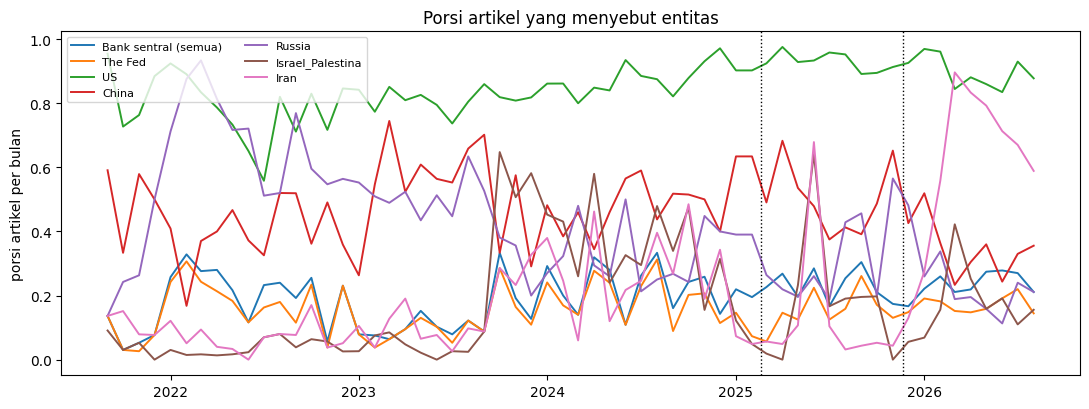

In [20]:
sp = articles.loc[has_split, "aligned_trading_date"].dt.to_period("M").to_numpy()
plot_cols = {"Bank sentral (semua)": CB_ANY, "The Fed": CB_FED}
for g in ("US", "China", "Russia", "Israel_Palestina", "Iran"):
    plot_cols[g] = C_FLAG[:, cg.index(g)]
mon = pd.DataFrame({k: v[has_split] for k, v in plot_cols.items()}).groupby(sp).mean()
fig, ax = plt.subplots(figsize=(11, 4.2))
for c in mon.columns: ax.plot(mon.index.to_timestamp(), mon[c], label=c, lw=1.4)
for key in ("train", "val"): ax.axvline(pd.Timestamp(splits[key]["end"]), color="k", ls=":", lw=1)
ax.set_ylabel("porsi artikel per bulan"); ax.set_title("Porsi artikel yang menyebut entitas")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()

## 6. Fitur harian

- **Porsi (E1/E2/E3):** rata-rata penanda (0/1) pada artikel hari itu = porsi artikel yang menyebut entitas. Hari tanpa berita diisi **porsi rata-rata hari train**. E1 memakai **8 negara terbesar di train** supaya fiturnya tidak terlalu banyak.
- **Sentimen terfilter (F):** rata-rata sentimen **hanya** dari artikel yang menyebut bank sentral / peristiwa ekonomi / AS. Sumber sentimen: VADER judul, LM isi (dari `sentiment_articles`), dan FinBERT (bila cache ada). Hari tanpa artikel yang cocok diisi 0.

In [21]:
has_news = (daily["news_count"] > 0).to_numpy()

def daily_mean(M):
    '''Rata-rata per aligned_trading_date; hari tanpa berita = rata-rata hari train (netral).'''
    df = pd.DataFrame(M[has_split]); df["date"] = articles.loc[has_split, "aligned_trading_date"].to_numpy()
    d = df.groupby("date").mean().reindex(daily["date"])
    has = d.notna().all(axis=1).to_numpy(); out = d.to_numpy(float).copy()
    out[~has] = out[tr & has].mean(axis=0)
    return out

def filtered_mean(mask, values):
    df = pd.DataFrame({"date": articles.loc[has_split & mask, "aligned_trading_date"].to_numpy(),
                       "v": values[has_split & mask]})
    return df.groupby("date")["v"].mean().reindex(daily["date"]).fillna(0.0).to_numpy()

# sentimen per artikel
SA = pd.read_parquet(EXPORT_DIR / "sentiment_articles.parquet").set_index("article_id").reindex(articles["article_id"])
SENT = {"vader_judul": SA["vader_title"].to_numpy(float), "lm_isi": SA["lm_text_net"].to_numpy(float)}
FB_OK = False
fb_f = CACHE_DIR / "FinBERT_cw300_mc2_ml512.npz"
if fb_f.exists():
    z = np.load(fb_f, allow_pickle=True); lab = {v: k for k, v in z["labels"].item().items()}
    SENT["finbert"] = z["P"][:, lab["positive"]] - z["P"][:, lab["negative"]]; FB_OK = True
else:
    print("cache FinBERT belum ada -> sentimen FinBERT dilewati")

FEAT = {}
top8 = list(np.argsort(-C_FLAG[is_tr].mean(0))[:8])
E1 = daily_mean(C_FLAG[:, top8].astype(float)); n1 = [f"neg_{cg[j]}" for j in top8]
E2 = daily_mean(np.stack([CB_ANY, CB_FED, CB_OTHER], 1).astype(float)); n2 = ["cb_semua", "cb_Fed", "cb_lain"]
E3 = daily_mean(EV_FLAG.astype(float)); n3 = [f"ev_{g}" for g in evg]
masks = {"cb": CB_ANY, "ekonomi": ECON_ANY, "AS": US_FLAG}
F_cols, F_names = [], []
for gname, msk in masks.items():
    for sname, vals in SENT.items():
        F_cols.append(filtered_mean(msk, vals)); F_names.append(f"{gname}_{sname}")
F = np.stack(F_cols, 1)
NAMES = {"E1 negara (8)": n1, "E2 bank sentral (3)": n2, "E3 peristiwa ekonomi (11)": n3, "F sentimen terfilter": F_names}
FEAT["E1 negara (8)"] = E1; FEAT["E2 bank sentral (3)"] = E2; FEAT["E3 peristiwa ekonomi (11)"] = E3
FEAT["E-semua (22)"] = np.hstack([E1, E2, E3]); FEAT["F sentimen terfilter"] = F
FEAT["E2+F"] = np.hstack([E2, F])
if FB_OK:
    FEAT["G sentimen FinBERT global (1 fitur)"] = daily_mean(SENT["finbert"][:, None])
print({k: v.shape for k, v in FEAT.items()})
print("hari dengan >=1 artikel terfilter: cb", int((F[:, 0] != 0).sum()), "| ekonomi", int((F[:, len(SENT)] != 0).sum()),
      "| AS", int((F[:, 2 * len(SENT)] != 0).sum()), "dari", len(daily), "hari")

{'E1 negara (8)': (1194, 8), 'E2 bank sentral (3)': (1194, 3), 'E3 peristiwa ekonomi (11)': (1194, 11), 'E-semua (22)': (1194, 22), 'F sentimen terfilter': (1194, 9), 'E2+F': (1194, 12), 'G sentimen FinBERT global (1 fitur)': (1194, 1)}
hari dengan >=1 artikel terfilter: cb 401 | ekonomi 799 | AS 899 dari 1194 hari


### Korelasi dengan target (hanya hari train yang punya berita)
Spearman fitur vs target (return besok). Karena puluhan fitur diuji, p dikoreksi **Bonferroni** (`p_bonf` = p × jumlah uji). Hanya `p_bonf < 0,05` yang pantas disebut hubungan nyata.

In [22]:
rows_c = []
m_tr = tr & has_news
mats = {"E1 negara (8)": (E1, n1), "E2 bank sentral (3)": (E2, n2), "E3 peristiwa ekonomi (11)": (E3, n3), "F sentimen terfilter": (F, F_names)}
for set_name, (M, names) in mats.items():
    for j, nm in enumerate(names):
        if M[m_tr, j].std() == 0: continue
        rho, p = spearmanr(M[m_tr, j], y[m_tr]); rows_c.append((set_name, nm, rho, p))
corr = pd.DataFrame(rows_c, columns=["set", "fitur", "rho", "p"])
corr["p_bonf"] = (corr["p"] * len(corr)).clip(upper=1.0)
print(f"{len(corr)} uji | n hari = {int(m_tr.sum())} | |rho| >= {1.96 / np.sqrt(m_tr.sum()):.3f} untuk p<0,05 tanpa koreksi")
corr.sort_values("p").head(12).round(4)

31 uji | n hari = 734 | |rho| >= 0.072 untuk p<0,05 tanpa koreksi


,set,fitur,rho,p,p_bonf
15,E3 peristiwa ekonomi (11),ev_sanksi,0.1014,0.0060,0.1854
10,E2 bank sentral (3),cb_lain,0.0708,0.0553,1.0000
21,E3 peristiwa ekonomi (11),ev_mata_uang,0.0633,0.0865,1.0000
1,E1 negara (8),neg_Russia,0.0619,0.0940,1.0000
11,E3 peristiwa ekonomi (11),ev_keputusan_suku_bunga,0.0558,0.1308,1.0000
20,E3 peristiwa ekonomi (11),ev_krisis_bank,-0.0495,0.1801,1.0000
25,F sentimen terfilter,ekonomi_vader_judul,-0.0456,0.2174,1.0000
2,E1 negara (8),neg_Ukraina,0.0400,0.2792,1.0000
30,F sentimen terfilter,AS_finbert,-0.0378,0.3061,1.0000
8,E2 bank sentral (3),cb_semua,0.0350,0.3433,1.0000


## 7. Protokol evaluasi (identik dengan notebook sebelumnya)

In [23]:
MODELS = {
    "Ridge": lambda s: Ridge(alpha=10.0),
    "RandForest": lambda s: RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=s),
    "GradBoost": lambda s: GradientBoostingRegressor(n_estimators=150, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=s),
}
SEEDS = (0, 1, 2)

def direction_metrics(y_true, y_pred):
    m = y_true != 0
    t, p = y_true[m] > 0, y_pred[m] > 0
    return {"BalAcc": balanced_accuracy_score(t, p), "MCC": matthews_corrcoef(t, p)}

def fit_predict(X):
    Xs = StandardScaler().fit(X[tr]).transform(X)
    preds = {}
    for name, make in MODELS.items():
        seeds = (0,) if name == "Ridge" else SEEDS
        preds[name] = np.mean([make(s).fit(Xs[tr], y[tr]).predict(Xs) for s in seeds], axis=0)
    return preds

rows = []
def run(set_name, X):
    for mname, p in fit_predict(X).items():
        for sp, mask in (("val", va), ("test", te)):
            r = evaluate(y[mask], p[mask]); r.update(direction_metrics(y[mask], p[mask]))
            rows.append(dict(set=set_name, model=mname, split=sp, **r))

ret_today = daily["ret"].to_numpy(); base_rows = []
for sp, mask in (("val", va), ("test", te)):
    nb = naive_baselines(y[mask], ret_today[mask])
    nb["Konstan (mean train)"] = evaluate(y[mask], np.full(mask.sum(), y[tr].mean()))
    preds = {"Prediksi 0": np.zeros(mask.sum()), "Return kemarin": ret_today[mask],
             "Konstan (mean train)": np.full(mask.sum(), y[tr].mean())}
    for name, r in nb.items():
        r = dict(r); r.update(direction_metrics(y[mask], preds[name]))
        base_rows.append(dict(set=name, model="-", split=sp, **r))

In [24]:
KURS = daily[KURS_COLS].to_numpy(); LEX = daily[LEX_COLS].to_numpy()
run("A  kurs", KURS)
run("B  kurs+lexicon", np.hstack([KURS, LEX]))
for name, M in FEAT.items():
    run(f"N  {name}" if not name.startswith("G ") else name, np.hstack([KURS, M]))
res = pd.DataFrame(rows); base = pd.DataFrame(base_rows)
print("selesai:", res["set"].nunique(), "set x", res["model"].nunique(), "model")

selesai: 9 set x 3 model


## 8. Hasil

### 8.1 Pembanding tanpa model

In [25]:
cols = ["MAE", "RMSE", "DirAcc", "BalAcc", "MCC"]
base.pivot(index="set", columns="split", values=cols).round(5)

MAE              RMSE            DirAcc          BalAcc               MCC         
split                    test      val     test      val     test      val   test      val     test      val
set                                                                                                         
Konstan (mean train)  0.00218  0.00246  0.00289  0.00338  0.59091  0.53409  0.500  0.50000  0.00000  0.00000
Prediksi 0            0.00221  0.00247  0.00291  0.00338  0.00000  0.00000  0.500  0.50000  0.00000  0.00000
Return kemarin        0.00308  0.00347  0.00398  0.00461  0.54545  0.50568  0.539  0.50908  0.07754  0.01816

### 8.2 Rata-rata 3 model per set fitur
`dRMSE%` terhadap A (negatif = lebih baik).

In [26]:
mean_tbl = res.groupby(["set", "split"])[["RMSE", "DirAcc", "BalAcc", "MCC"]].mean().unstack("split")
a_rmse = mean_tbl.loc["A  kurs", "RMSE"]
for sp in ("val", "test"):
    mean_tbl[("dRMSE%", sp)] = (mean_tbl[("RMSE", sp)] / a_rmse[sp] - 1) * 100
mean_tbl = mean_tbl.sort_values(("RMSE", "val"))
mean_tbl.round(5)

RMSE            DirAcc            BalAcc               MCC            dRMSE%         
split                                   test      val     test      val     test      val     test      val      val     test
set                                                                                                                          
N  E1 negara (8)                     0.00298  0.00342  0.44886  0.46402  0.52012  0.48629  0.06950 -0.03523 -0.35134 -1.71603
N  E2 bank sentral (3)               0.00300  0.00343  0.42803  0.46591  0.50107  0.49040  0.00281 -0.02775 -0.18973 -1.03549
N  E-semua (22)                      0.00296  0.00343  0.47727  0.46970  0.52778  0.48512  0.06713 -0.03848 -0.15851 -2.07399
A  kurs                              0.00303  0.00343  0.40720  0.47159  0.49769  0.49728 -0.03028 -0.01454  0.00000  0.00000
N  E3 peristiwa ekonomi (11)         0.00299  0.00344  0.46023  0.48485  0.51549  0.50138  0.02961  0.00592  0.04416 -1.23911
N  E2+F                              0.00306  0.00344  0.43182  0.48674  0.49074  0.50601 -0.02610  0.01273  0.25599  0.95595
N  F sentimen terfilter              0.00306  0.00345  0.44886  0.51326  0.50873  0.53031  0.02157  0.06966  0.40483  0.95639
B  kurs+lexicon                      0.00301  0.00346  0.44318  0.45644  0.49181  0.47557 -0.02755 -0.04702  0.62909 -0.47218
G sentimen FinBERT global (1 fitur)  0.00306  0.00346  0.40909  0.46591  0.49858  0.49118 -0.01593 -0.03051  0.81739  1.00725

### 8.3 Per model (RMSE val)

In [27]:
pm = res[res["split"] == "val"].pivot(index="set", columns="model", values="RMSE")
pm["rata2"] = pm.mean(axis=1); pm.sort_values("rata2").round(6)

model,GradBoost,RandForest,Ridge,rata2
set,,,,
N E1 negara (8),0.003410,0.003459,0.003397,0.003422
N E2 bank sentral (3),0.003418,0.003482,0.003383,0.003427
N E-semua (22),0.003433,0.003421,0.003431,0.003428
A kurs,0.003421,0.003493,0.003388,0.003434
N E3 peristiwa ekonomi (11),0.003432,0.003450,0.003424,0.003435
N E2+F,0.003446,0.003482,0.003400,0.003443
N F sentimen terfilter,0.003454,0.003485,0.003405,0.003448
B kurs+lexicon,0.003449,0.003493,0.003424,0.003456
G sentimen FinBERT global (1 fitur),0.003478,0.003517,0.003392,0.003462


### 8.4 Grafik

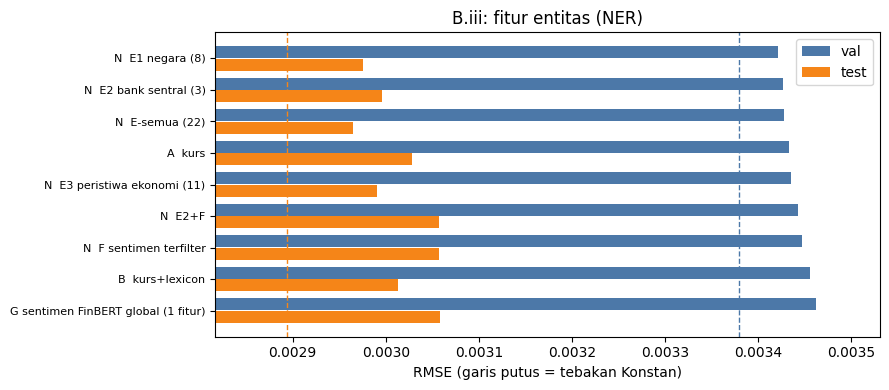

In [28]:
plot_df = mean_tbl["RMSE"].sort_values("val", ascending=False)
const = base[base["set"] == "Konstan (mean train)"].set_index("split")["RMSE"]
fig, ax = plt.subplots(figsize=(9, max(4, 0.34 * len(plot_df))))
yy = np.arange(len(plot_df))
ax.barh(yy + 0.2, plot_df["val"], height=0.38, label="val", color="#4C78A8")
ax.barh(yy - 0.2, plot_df["test"], height=0.38, label="test", color="#F58518")
ax.axvline(const["val"], color="#4C78A8", ls="--", lw=1); ax.axvline(const["test"], color="#F58518", ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=8)
ax.set_xlim(plot_df.min().min() * 0.95, plot_df.max().max() * 1.02)
ax.set_xlabel("RMSE (garis putus = tebakan Konstan)"); ax.legend()
ax.set_title("B.iii: fitur entitas (NER)"); plt.tight_layout(); plt.show()

## 9. Catatan metodologi
- **Tidak ada kebocoran:** NER dan kamus tidak dilatih pada data kita. Kamus disusun dari statistik entitas, bukan dari performa val/test. Fitur harian hanya memakai rata-rata per hari, dan nilai pengisi hari kosong dihitung dari hari train.
- **NER mentah tidak andal** untuk domain ini (lihat 4.2 dan 4.4). Karena itu kamus alias dan aturan pola dipakai sebagai filter. Metode ini transparan tapi bergantung pada kualitas kamus.
- **"Washington", "White House", "Pentagon"** dipetakan ke AS; "Washington" kadang bisa berarti negara bagian. Ini kompromi.
- **Banyak uji:** puluhan fitur diuji, jadi sebagian "temuan" kebetulan. Pakai `p_bonf` dan kekonsistenan val/test.
- **Pembanding utama tetap baris Konstan.** Selisih < 1-2% anggap noise kecuali konsisten.

## 10. Kesimpulan 
1. **H3:** berapa % artikel memuat bank sentral dan peristiwa ekonomi? Seberapa besar noise NER mentah (4.2)? Dari cek presisi 4.5, berapa dari 12 cuplikan yang benar-benar relevan? Apakah kamus teks menangkap lebih banyak bank sentral daripada NER saja (4.3)?
cukup andal untuk deskripsi. Bank sentral muncul di 22% artikel, peristiwa ekonomi di 72%, dan grafik waktunya cocok dengan peristiwa nyata (perang Ukraina 2022, perang Iran 2026). Kelemahannya: NER mentah noisy (CNBC, Trump, AI), NER hampir tidak menambah apa pun di atas kamus untuk bank sentral, kamus belum memuat Middle East, Hormuz, dan NATO, dan penanda tingkat artikel tidak membedakan "membahas" dari "menyebut sambil lalu".

2. **H1:** apakah E1/E2/E3/E-semua konsisten lebih baik dari A di val **dan** test? Berapa dRMSE%?
tidak terbukti. Selisih RMSE terhadap A ada di rentang sekitar −2% sampai +0,05%, dengan val hampir nol dan gain hanya di test, jadi masih noise. Fiturnya juga bergeser antar periode (Iran ≈ 0 di train, dominan di test).

3. **H2:** apakah sentimen terfilter (F) lebih baik dari sentimen global (G atau B)? Ada fitur dengan `p_bonf` < 0,05?
tidak terdukung. F +0,4% dan +1,0% terhadap A, hampir sama dengan sentimen global G, jadi memfilter berdasarkan entitas tidak membuat sentimen lebih informatif.

4. Apakah ada set yang mengalahkan baris Konstan?
korelasi terkuat (ev_sanksi, rho 0,10) tidak lolos Bonferroni (p_bonf 0,185 dari 31 uji).

5. Apakah fitur entitas layak masuk Model C, atau cukup sebagai analisis deskriptif?
fitur entitas (negara, bank sentral, peristiwa ekonomi) tidak meningkatkan prediksi return USD/IDR secara berarti.